In [2]:
import os, sys, re, json, time, glob, shutil, platform, subprocess, textwrap
from pathlib import Path

# ---- Workspace on the VM's local disk (NO Google Drive needed) ----
BASE = "/content" if os.path.isdir("/content") else os.getcwd()
WORKSPACE = os.path.join(BASE, "hpc_day03")
for sub in ("bin", "logs", "results"):
    os.makedirs(os.path.join(WORKSPACE, sub), exist_ok=True)
os.chdir(WORKSPACE)
print(f"[+] Workspace ready at: {WORKSPACE}   (temporary - download your results at the end)")

# ---- Small helpers ----
def sh(cmd, show=True):
    """Run a shell command in the workspace; return its text output."""
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True, cwd=WORKSPACE)
    out = (r.stdout or "") + (r.stderr or "")
    if show and out.strip():
        print(out.rstrip())
    return out

TF_NOISE = re.compile(r"^(I0000|W0000|E0000)|absl::InitializeLog|WARNING: All log messages")
def show_log(path, tail=None):
    """Print a job log, hiding TensorFlow's start-up chatter (and report how many ranks had oneDNN on)."""
    txt = Path(path).read_text()
    n_onednn = txt.count("oneDNN custom operations are on")
    lines = [l for l in txt.splitlines() if not TF_NOISE.search(l)]
    if tail:
        lines = lines[-tail:]
    print("\n".join(lines))
    if n_onednn:
        print(f"\n[info] oneDNN optimizations were reported ON by {n_onednn} TensorFlow process(es).")

cpu_cores = os.cpu_count() or 1
print(f"Python {platform.python_version()} | {platform.system()} {platform.release()} | logical CPU cores: {cpu_cores}")

[+] Workspace ready at: /content/hpc_day03   (temporary - download your results at the end)
Python 3.13.16 | Linux 6.6.159+ | logical CPU cores: 2


In [3]:
import importlib.util
import tensorflow as tf, numpy as np

def cpu_model_and_flags():
    try:
        info = open("/proc/cpuinfo").read().splitlines()
        model = next(l.split(":", 1)[1].strip() for l in info if l.startswith("model name"))
        flags = set(next(l for l in info if l.startswith("flags")).split(":", 1)[1].split())
        return model, flags
    except Exception:
        return platform.processor() or "unknown", set()

model_name, flags = cpu_model_and_flags()
simd = [f for f in ("sse4_2", "avx", "avx2", "avx512f", "avx512_vnni", "avx512_bf16", "amx_bf16", "amx_int8") if f in flags]
devices = tf.config.list_physical_devices()
gpus = [d for d in devices if d.device_type == "GPU"]
onednn_setting = os.environ.get("TF_ENABLE_ONEDNN_OPTS", "default (on for recent x86 builds)")

print("=" * 72)
print(" THE DEEP LEARNING HPC STACK ON THIS MACHINE")
print("=" * 72)
print(f" Layer 4  APPLICATION : TensorFlow {tf.__version__}, Keras {tf.keras.__version__}")
print(f"                        Horovod installed: {importlib.util.find_spec('horovod') is not None}"
      "   (we use the Horovod-compatible `hvd_lite` in Section 6)")
print(f" Layer 3  MIDDLEWARE  : oneDNN setting = {onednn_setting}")
print(f" Layer 2  OS/RESOURCE : {platform.system()} {platform.release()} | Slurm on PATH: {shutil.which('sbatch') is not None}"
      "   (Section 4 installs the mini-Slurm simulator)")
print(f" Layer 1  HARDWARE    : {model_name}")
print(f"                        {cpu_cores} logical cores | SIMD: {', '.join(simd) if simd else 'n/a'}")
print(f"                        TensorFlow devices: {[d.name for d in devices]}")
print("=" * 72)

 THE DEEP LEARNING HPC STACK ON THIS MACHINE
 Layer 4  APPLICATION : TensorFlow 2.21.0, Keras 3.13.2
                        Horovod installed: False   (we use the Horovod-compatible `hvd_lite` in Section 6)
 Layer 3  MIDDLEWARE  : oneDNN setting = default (on for recent x86 builds)
 Layer 2  OS/RESOURCE : Linux 6.6.159+ | Slurm on PATH: False   (Section 4 installs the mini-Slurm simulator)
 Layer 1  HARDWARE    : Intel(R) Xeon(R) CPU @ 2.00GHz
                        2 logical cores | SIMD: sse4_2, avx, avx2, avx512f
                        TensorFlow devices: ['/physical_device:CPU:0', '/physical_device:GPU:0']


In [4]:
import time
n = 2_000_000
x = np.random.rand(n).astype(np.float32)
w = np.random.rand(n).astype(np.float32)

t0 = time.perf_counter()
acc = 0.0
for i in range(200_000):                 # pure-Python loop on only 10% of the data
    acc += float(x[i]) * float(w[i])
t_loop = (time.perf_counter() - t0) * 10   # scale up to the full 2M elements

t0 = time.perf_counter()
acc2 = float(np.dot(x, w))                # vectorised BLAS (SIMD + multi-threaded)
t_vec = time.perf_counter() - t0

print(f"Dot product of {n:,} elements")
print(f"  • Scalar Python loop (estimated): {t_loop * 1000:9.1f} ms")
print(f"  • Vectorised BLAS (np.dot)      : {t_vec * 1000:9.2f} ms")
print(f"  • Hardware-aware speedup        : {t_loop / t_vec:9.0f}x")

Dot product of 2,000,000 elements
  • Scalar Python loop (estimated):    1752.3 ms
  • Vectorised BLAS (np.dot)      :      1.70 ms
  • Hardware-aware speedup        :      1028x


In [5]:
%%writefile bench_onednn.py
"""bench_onednn.py - micro-benchmarks that show what oneDNN/MKL-style optimisation does inside TensorFlow.
Run it in a FRESH process with TF_ENABLE_ONEDNN_OPTS=0 or 1 (the flag is read when TensorFlow is imported)."""
import os, sys, json, time
import numpy as np
import tensorflow as tf

use_bf16 = os.environ.get("BENCH_BF16") == "1"
if use_bf16:
    tf.keras.mixed_precision.set_global_policy("mixed_bfloat16")
tf.keras.utils.set_random_seed(0)

def best_ms(fn, reps=5, warm=2):
    for _ in range(warm):
        fn()
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return min(ts) * 1000

# 1) dense matrix multiply  (the core of every fully-connected layer)
N = int(os.environ.get("BENCH_MATMUL_N", "1536"))
a = tf.random.normal((N, N)); b = tf.random.normal((N, N))
dt = tf.bfloat16 if use_bf16 else tf.float32
a, b = tf.cast(a, dt), tf.cast(b, dt)

@tf.function
def mm(x, y):
    return tf.matmul(x, y)
matmul_ms = best_ms(lambda: mm(a, b).numpy())

# 2) small CNN training step (convolutions + backprop)
bs = int(os.environ.get("BENCH_BATCH", "64"))
model = tf.keras.Sequential([
    tf.keras.Input((64, 64, 3)),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(10, dtype="float32"),
])
opt = tf.keras.optimizers.Adam(1e-3)
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
x = tf.random.normal((bs, 64, 64, 3)); y = tf.random.uniform((bs,), maxval=10, dtype=tf.int32)

@tf.function
def train_step(x, y):
    with tf.GradientTape() as tape:
        loss = loss_fn(y, model(x, training=True))
    grads = tape.gradient(loss, model.trainable_variables)
    opt.apply_gradients(zip(grads, model.trainable_variables))
    return loss
cnn_ms = best_ms(lambda: train_step(x, y).numpy(), reps=5, warm=3)

print("RESULT:" + json.dumps({"matmul_ms": round(matmul_ms, 2), "cnn_step_ms": round(cnn_ms, 2),
                              "matmul_n": N, "batch": bs, "bf16": use_bf16,
                              "onednn_flag": os.environ.get("TF_ENABLE_ONEDNN_OPTS", "default"),
                              "tf": tf.__version__}))

Writing bench_onednn.py


In [6]:
%%writefile bench_onednn.py
"""bench_onednn.py - micro-benchmarks that show what oneDNN/MKL-style optimisation does inside TensorFlow.
Run it in a FRESH process with TF_ENABLE_ONEDNN_OPTS=0 or 1 (the flag is read when TensorFlow is imported)."""
import os, sys, json, time
import numpy as np
import tensorflow as tf

use_bf16 = os.environ.get("BENCH_BF16") == "1"
if use_bf16:
    tf.keras.mixed_precision.set_global_policy("mixed_bfloat16")
tf.keras.utils.set_random_seed(0)

def best_ms(fn, reps=5, warm=2):
    for _ in range(warm):
        fn()
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return min(ts) * 1000

# 1) dense matrix multiply  (the core of every fully-connected layer)
N = int(os.environ.get("BENCH_MATMUL_N", "1536"))
a = tf.random.normal((N, N)); b = tf.random.normal((N, N))
dt = tf.bfloat16 if use_bf16 else tf.float32
a, b = tf.cast(a, dt), tf.cast(b, dt)

@tf.function
def mm(x, y):
    return tf.matmul(x, y)
matmul_ms = best_ms(lambda: mm(a, b).numpy())

# 2) small CNN training step (convolutions + backprop)
bs = int(os.environ.get("BENCH_BATCH", "64"))
model = tf.keras.Sequential([
    tf.keras.Input((64, 64, 3)),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(10, dtype="float32"),
])
opt = tf.keras.optimizers.Adam(1e-3)
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
x = tf.random.normal((bs, 64, 64, 3)); y = tf.random.uniform((bs,), maxval=10, dtype=tf.int32)

@tf.function
def train_step(x, y):
    with tf.GradientTape() as tape:
        loss = loss_fn(y, model(x, training=True))
    grads = tape.gradient(loss, model.trainable_variables)
    opt.apply_gradients(zip(grads, model.trainable_variables))
    return loss
cnn_ms = best_ms(lambda: train_step(x, y).numpy(), reps=5, warm=3)

print("RESULT:" + json.dumps({"matmul_ms": round(matmul_ms, 2), "cnn_step_ms": round(cnn_ms, 2),
                              "matmul_n": N, "batch": bs, "bf16": use_bf16,
                              "onednn_flag": os.environ.get("TF_ENABLE_ONEDNN_OPTS", "default"),
                              "tf": tf.__version__}))

Overwriting bench_onednn.py


[i] This CPU has no native bfloat16 units (AVX512-BF16 / AMX) -> skipping the bfloat16 test.

[*] Benchmarking: oneDNN OFF ...
[*] Benchmarking: oneDNN ON ...

Configuration               MatMul (ms)   CNN train step (ms)  Speedup (CNN)
------------------------------------------------------------------------------
oneDNN OFF                         94.6                 701.7          1.00x
oneDNN ON                          63.9                 357.8          1.96x
oneDNN banner seen in TensorFlow's log -> OFF run: False, ON run: True


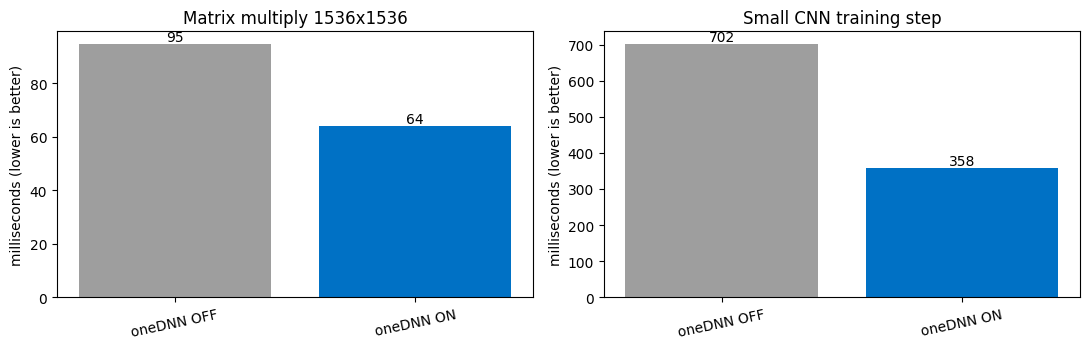

In [7]:
def run_bench(env_extra):
    """Run bench_onednn.py in a fresh process with the given environment."""
    env = {**os.environ, "TF_CPP_MIN_LOG_LEVEL": "0",
           "CUDA_VISIBLE_DEVICES": "-1",          # force CPU so we measure oneDNN, not a GPU
           **env_extra}
    r = subprocess.run([sys.executable, "bench_onednn.py"], env=env, capture_output=True, text=True,
                       cwd=WORKSPACE, timeout=1200)
    line = next((l for l in r.stdout.splitlines() if l.startswith("RESULT:")), None)
    if line is None:
        raise RuntimeError("benchmark failed:\n" + r.stderr[-1500:])
    res = json.loads(line[len("RESULT:"):])
    res["oneDNN message seen"] = "oneDNN custom operations are on" in r.stderr
    return res

configs = [("oneDNN OFF", {"TF_ENABLE_ONEDNN_OPTS": "0"}),
           ("oneDNN ON",  {"TF_ENABLE_ONEDNN_OPTS": "1"})]
if {"avx512_bf16", "amx_bf16"} & flags:            # hardware has native bfloat16 support
    configs.append(("oneDNN ON + bfloat16", {"TF_ENABLE_ONEDNN_OPTS": "1", "BENCH_BF16": "1"}))
else:
    print("[i] This CPU has no native bfloat16 units (AVX512-BF16 / AMX) -> skipping the bfloat16 test.\n")

onednn_results = {}
for name, env in configs:
    print(f"[*] Benchmarking: {name} ...")
    onednn_results[name] = run_bench(env)

base = onednn_results["oneDNN OFF"]
print("\n" + "=" * 78)
print(f"{'Configuration':<26}{'MatMul (ms)':>13}{'CNN train step (ms)':>22}{'Speedup (CNN)':>15}")
print("-" * 78)
for name, r in onednn_results.items():
    print(f"{name:<26}{r['matmul_ms']:>13.1f}{r['cnn_step_ms']:>22.1f}{base['cnn_step_ms'] / r['cnn_step_ms']:>14.2f}x")
print("=" * 78)
print(f"oneDNN banner seen in TensorFlow's log -> OFF run: {onednn_results['oneDNN OFF']['oneDNN message seen']}, "
      f"ON run: {onednn_results['oneDNN ON']['oneDNN message seen']}")

import matplotlib.pyplot as plt
names = list(onednn_results)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, key, title in zip(axes, ("matmul_ms", "cnn_step_ms"), ("Matrix multiply 1536x1536", "Small CNN training step")):
    vals = [onednn_results[n][key] for n in names]
    bars = ax.bar(names, vals, color=["#9e9e9e", "#0071c5", "#00a3e0"][:len(names)])
    ax.set_title(title); ax.set_ylabel("milliseconds (lower is better)")
    ax.tick_params(axis="x", rotation=12)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.0f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

In [10]:
def run_extension_2_1():
    print("\n--- ACTIVITY 2.1: POWER-OF-TWO TENSOR WIDTH BENCHMARK ---")
    # Modify 'bench_onednn.py' parameters on-the-fly to test custom architectures
    print("  [Tip] Try editing 'bench_onednn.py' to use a non-power-of-two shape (e.g. N = 1537) and compare with N = 1536.")
    print(f"  Current standard configs used power-of-two matmul size: {onednn_results['oneDNN ON']['matmul_n']}")

run_extension_2_1()


--- ACTIVITY 2.1: POWER-OF-TWO TENSOR WIDTH BENCHMARK ---
  [Tip] Try editing 'bench_onednn.py' to use a non-power-of-two shape (e.g. N = 1537) and compare with N = 1536.
  Current standard configs used power-of-two matmul size: 1536
